# Pharmacological Network Analytics and Exploratory Data Analysis (EDA)

**Abstract / Project Goal:**
This project focuses on extracting actionable pharmacological insights from the hierarchical DrugBank XML database. By programmatically parsing nested biomedical records into structured relational formats, the pipeline models complex drug-pathway interactions, target protein localizations, and active ingredient distributions.

**Data Source & Methodology:**
Data is extracted using a memory-efficient `lxml` iterative parser. The output is processed via `pandas` and modeled conceptually utilizing `NetworkX` for bipartite and hierarchical graphs. Aggregate analytics are visualized interactively via `Plotly`.

In [1]:
from src.data_parser import DrugBankParser
from src.network_visualizer import PharmaVisualizer

# Initialize memory-efficient XML Parser
parser = DrugBankParser("data/drugbank_partial.xml")

## 1. General Drug Information Extraction
Extracting basic drug information: ID, Name, Type, Description, Form, Indication, Mechanism of Action, and Food Interactions.

In [2]:
df_drugs = parser.extract_basic_info()
display(df_drugs.head())

,DrugBank_ID,Name,Type,Description,Form,Indication,Mechanism_of_Action,Food_Interactions
0,DB00001,Lepirudin,biotech,Lepirudin is a recombinant hirudin formed by 6...,solid,Lepirudin is indicated for anticoagulation in ...,Lepirudin is a direct thrombin inhibitor used ...,Avoid herbs and supplements with anticoagulant...
1,DB00002,Cetuximab,biotech,Cetuximab is a recombinant chimeric human/mous...,liquid,Cetuximab indicated for the treatment of local...,The epidermal growth factor receptor (EGFR) is...,
2,DB00003,Dornase alfa,biotech,Dornase alfa is a biosynthetic form of human d...,liquid,Used as adjunct therapy in the treatment of cy...,Dornase alfa is a biosynthetic form of human D...,
3,DB00004,Denileukin diftitox,biotech,A recombinant DNA-derived cytotoxic protein co...,liquid,For treatment of cutaneous T-cell lymphoma,Denileukin diftitox binds to the high-affinity...,
4,DB00005,Etanercept,biotech,Dimeric fusion protein consisting of the extra...,liquid,Etanercept is indicated for the treatment of m...,There are two distinct receptors for TNF (TNFR...,


## 2. Drug Synonyms Entity Extraction & Network Modeling
Extracting known market names and chemical synonyms and visualizing them via a star graph.

,DrugBank_ID,Name,Synonyms
0,DB00001,Lepirudin,"[[Leu1, Thr2]-63-desulfohirudin, Desulfatohiru..."
1,DB00002,Cetuximab,"[Cetuximab, Cétuximab, Cetuximabum]"
2,DB00003,Dornase alfa,[Deoxyribonuclease (human clone 18-1 protein m...
3,DB00004,Denileukin diftitox,"[Denileukin, Denileukin diftitox, Interleukin-..."
4,DB00005,Etanercept,"[Etanercept, etanercept-szzs, etanercept-ykro,..."


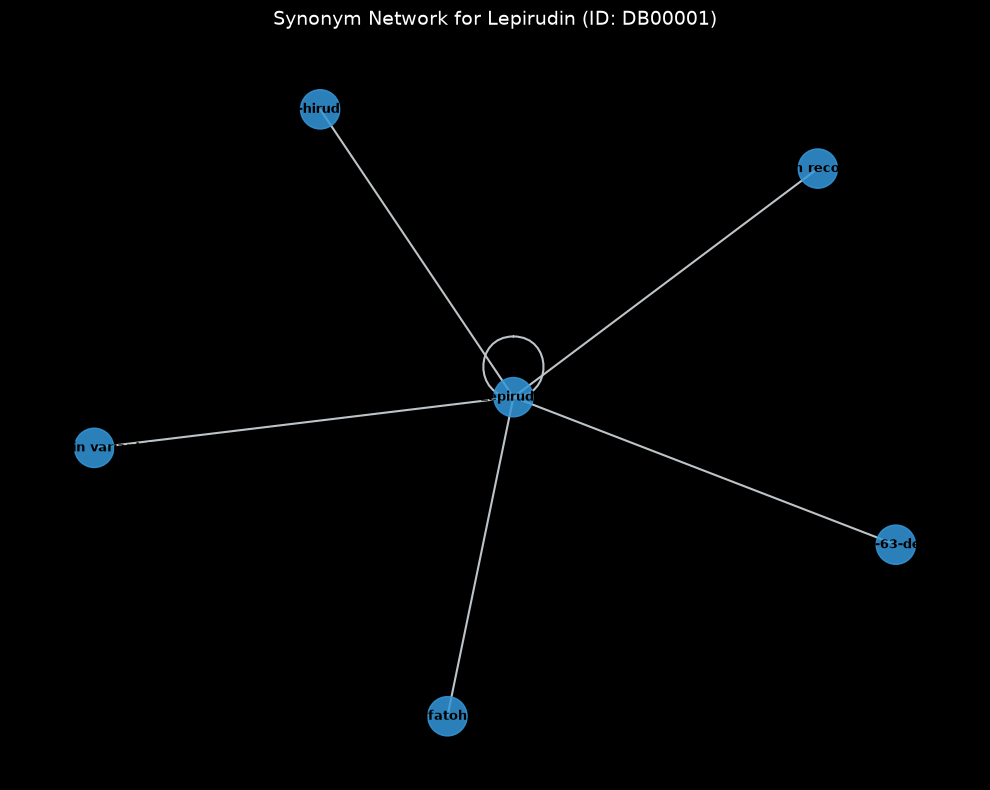

In [3]:
df_synonyms = parser.extract_drug_synonyms()
display(df_synonyms.head())
PharmaVisualizer.plot_synonym_network("DB00001", df_synonyms)

## 3. Pharmaceutical Products Catalog
Extracting product names, manufacturers, NDC codes, dosage forms, routes, and regulatory agencies.

In [4]:
df_products = parser.extract_products()
display(df_products.head())

,DrugBank_ID,Product_Name,Manufacturer,NDC_Code,Dosage_Form,Route,Strength,Country,Regulatory_Agency
0,DB00001,Refludan,Bayer,50419-150,Powder,Intravenous,50 mg/1mL,US,FDA NDC
1,DB00001,Refludan,Bayer,,"Powder, for solution",Intravenous,50 mg / vial,Canada,DPD
2,DB00001,Refludan,Celgene Europe Limited,,"Injection, solution, concentrate",Intravenous,50 mg,EU,EMA
3,DB00001,Refludan,Celgene Europe Limited,,"Injection, solution, concentrate",Intravenous,50 mg,EU,EMA
4,DB00001,Refludan,Celgene Europe Limited,,"Injection, solution, concentrate",Intravenous,20 mg,EU,EMA


## 4. Biological Pathway Analysis
Extracting pathway interactions, rendering bipartite networks, and aggregating pathway counts per drug.

Total Unique Pathways: 12


,Pathway_Name,Category,SMPDB_ID,Drug_Name,DrugBank_ID
0,Lepirudin Action Pathway,drug_action,SMP0000278,Lepirudin,DB00001
1,Lepirudin Action Pathway,drug_action,SMP0000278,Phylloquinone,DB01022
2,Lepirudin Action Pathway,drug_action,SMP0000278,Calcium,DB01373
3,Cetuximab Action Pathway,drug_action,SMP0000474,Cetuximab,DB00002
4,Bivalirudin Action Pathway,drug_action,SMP0000277,Bivalirudin,DB00006


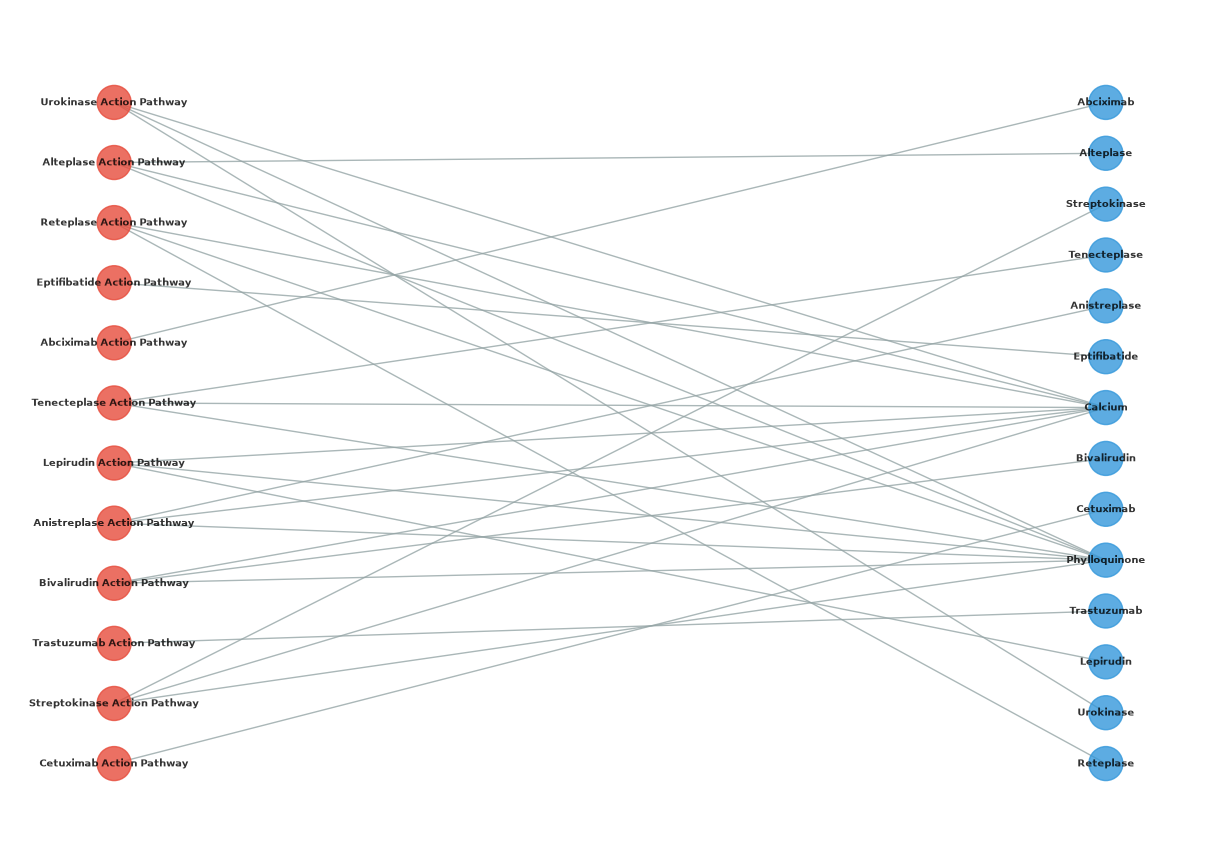

In [5]:
df_pathways = parser.extract_pathways()
print(f"Total Unique Pathways: {df_pathways['SMPDB_ID'].nunique()}")
display(df_pathways.head())

# Bipartite Network Visualization
PharmaVisualizer.plot_bipartite_pathway_network(df_pathways)

# Pathway frequency per drug
PharmaVisualizer.plot_pathway_counts(df_pathways)

## 5. Target Protein Profiling
Extracting target polypeptides, mapping them to GenAtlas IDs, and visualizing cellular localizations.

In [6]:
df_targets = parser.extract_targets()
display(df_targets.head())

# Target Cellular Distribution
PharmaVisualizer.plot_target_cellular_distribution(df_targets)

,DrugBank_ID,Target_ID,Target_Name,Source,External_ID,Polypeptide_Name,Gene_Name,GenAtlas_ID,Chromosome_Location,Cellular_Location
0,DB00001,BE0000048,Prothrombin,HUGO Gene Nomenclature Committee (HGNC),HGNC:3535,Prothrombin,F2,F2,11,Secreted
1,DB00002,BE0000767,Epidermal growth factor receptor,HUGO Gene Nomenclature Committee (HGNC),HGNC:3236,Epidermal growth factor receptor,EGFR,EGFR,7,Cell membrane
2,DB00002,BE0000901,Low affinity immunoglobulin gamma Fc region re...,HUGO Gene Nomenclature Committee (HGNC),HGNC:3620,Low affinity immunoglobulin gamma Fc region re...,FCGR3B,FCGR3B,1,Cell membrane
3,DB00002,BE0002094,Complement C1q subcomponent subunit A,HUGO Gene Nomenclature Committee (HGNC),HGNC:1241,Complement C1q subcomponent subunit A,C1QA,C1QA,1,Secreted
4,DB00002,BE0002095,Complement C1q subcomponent subunit B,HUGO Gene Nomenclature Committee (HGNC),HGNC:1242,Complement C1q subcomponent subunit B,C1QB,C1QB,1,Secreted


## 6. Regulatory Status Distribution
Analyzing the drug approval pipeline and quantifying active entities.

In [7]:
df_statuses = parser.extract_drug_statuses()

approved = set(df_statuses[df_statuses["Status_Group"] == "approved"]["DrugBank_ID"])
withdrawn = set(df_statuses[df_statuses["Status_Group"] == "withdrawn"]["DrugBank_ID"])
net_active_approved = len(approved - withdrawn)

print(f"Number of approved drugs that have not been withdrawn: {net_active_approved}")

PharmaVisualizer.plot_drug_approval_status(df_statuses)

Number of approved drugs that have not been withdrawn: 89


## 7. Drug-Drug Interactions (DDI)
Extracting drug-drug interaction pairs and generating histograms of DDI volume per entity.

In [8]:
df_interactions = parser.extract_drug_interactions()
display(df_interactions.head())

# DDI Volume per Entity
PharmaVisualizer.plot_drug_interactions_count(df_interactions)

,Drug_A_ID,Drug_A_Name,Drug_B_ID,Drug_B_Name
0,DB00001,Lepirudin,DB06605,Apixaban
1,DB00001,Lepirudin,DB06695,Dabigatran etexilate
2,DB00001,Lepirudin,DB01254,Dasatinib
3,DB00001,Lepirudin,DB01609,Deferasirox
4,DB00001,Lepirudin,DB01586,Ursodeoxycholic acid


## 8. Hierarchical Multi-Level Network Generation
Demonstrating an end-to-end biological and market relationship:
**Target Gene → Active Ingredient (DrugBank ID) → Market Products**

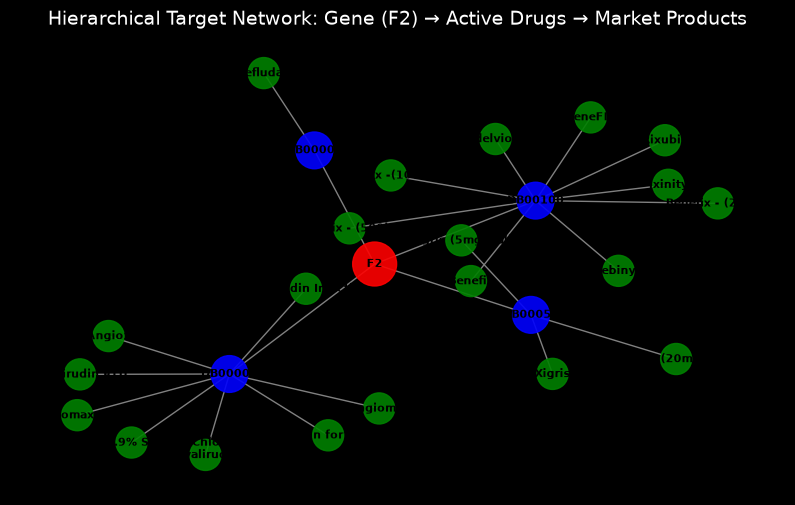

In [9]:
# Generating a custom hierarchical network for the F2 (Prothrombin) or EGFR gene
PharmaVisualizer.plot_gene_drug_product_network("F2", df_targets, df_products)

## 9. Mock Database Generation
Simulating a larger dataset by generating 20,000 drug records based on the statistical distribution of the original 100 records.

In [10]:
import os

from src.xml_simulator import generate_mock_database

input_xml = "data/drugbank_partial.xml"
output_xml = "data/drugbank_partial_and_generated.xml"

if not os.path.exists(output_xml):
    generate_mock_database(input_xml, output_xml, total_records=20000)
else:
    print(f"Mock database already exists at {output_xml}")

large_parser = DrugBankParser(output_xml)
df_large = large_parser.extract_basic_info()
print(f"\nSuccessfully parsed large database. Total records: {len(df_large)}")

Generating 19900 synthetic drug records...
Mock database saved to data/drugbank_partial_and_generated.xml with 20000 records.

Successfully parsed large database. Total records: 20000


## 10. Unit Testing
Ensuring code reliability and data integrity using `pytest`. The tests validate the XML extraction logic using a dummy fixture.

In [12]:
!pytest tests/test_parser.py -v

============================= test session starts ==============================
platform darwin -- Python 3.14.8, pytest-9.1.1, pluggy-1.7.0 -- /Users/pavelcharheika/Projects/University/MIMUW/sem-5/python/pharma-data-extraction-eda/.venv/bin/python3
cachedir: .pytest_cache
rootdir: /Users/pavelcharheika/Projects/University/MIMUW/sem-5/python/pharma-data-extraction-eda
configfile: pyproject.toml
plugins: anyio-4.15.1, platformdirs-4.13.5
collected 2 items                                                              

tests/test_parser.py::test_extract_basic_info PASSED                     [ 50%]
tests/test_parser.py::test_extract_pathways PASSED                       [100%]

============================== 2 passed in 1.09s ===============================


## 11. REST API Integration
Demonstrating a POST request to the local FastAPI server to retrieve the number of pathway interactions for a specific drug.
*Note: The server must be running locally via `uvicorn src.api:app --reload` before executing this cell.*

In [14]:
import requests

api_url = "http://127.0.0.1:8000/drug_interactions/"

payload = {"drug_name": "Lepirudin"}

try:
    response = requests.post(api_url, json=payload)
    if response.status_code == 200:
        data = response.json()
        print("API Response successful:")
        print(f"Drug: {data['drug_name']}")
        print(f"Interacting Pathways Count: {data['interaction_count']}")
    else:
        print(f"Error {response.status_code}: {response.text}")
except requests.exceptions.ConnectionError:
    print(
        "Connection Error: Is the FastAPI server running? Run `uvicorn src.api:app` in your terminal."
    )

API Response successful:
Drug: Lepirudin
Interacting Pathways Count: 1
